# Part 2 – Land-cover classification on Sentinel-2 (EuroSAT)

Fine-tuning and benchmarking of ResNet-50, Swin Transformer Tiny and EfficientNet-B0 (ImageNet-pretrained, via `timm`) on the EuroSAT RGB dataset (27,000 Sentinel-2 tiles, 10 classes), with a 70/15/15 train/validation/test split and 50 training epochs.


In [1]:
# Import Libraries
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, random_split
import torch
import torch.nn as nn
from tqdm import tqdm
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import timm
import gc
import time
import torch.optim as optim
import torchvision.transforms.functional as F

In [2]:
# Load dataset
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Upsampling
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

dataset = torchvision.datasets.EuroSAT(
    root='./data',
    download=True,
    transform=transform
)

In [3]:
# Load Model (Pretrained & Fine-tuning)
def load_model(model_name, num_classes=10):
    model = timm.create_model(model_name, pretrained=True, num_classes=num_classes)
    return model

In [4]:
# Split 70/15/15
total_len = len(dataset)
train_len = int(0.7 * total_len)
val_len = int(0.15 * total_len)
test_len = total_len - train_len - val_len
train_ds, val_ds, test_ds = random_split(dataset, [train_len, val_len, test_len])

In [5]:
# Training
def train_model(model, train_loader, val_loader, epochs, lr=1e-4, use_scheduler=False):

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)

    if use_scheduler:
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode='min', patience=3, factor=0.5
        )

    train_losses, train_accs = [], []
    val_losses, val_accs = [], []

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        correct = 0
        total = 0
        running_loss = 0.0

        for inputs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total
        train_losses.append(train_loss)
        train_accs.append(train_acc)
        print("Train Loss: {:.4f}, Train Accuracy: {:.4f}".format(train_loss, train_acc))

        # Validation 
        model.eval()
        val_correct = 0
        val_total = 0
        val_running_loss = 0.0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_running_loss / val_total
        val_acc = val_correct / val_total
        val_losses.append(val_loss)
        val_accs.append(val_acc)
        print("Validation Loss: {:.4f}, Validation Accuracy: {:.4f}".format(val_loss, val_acc))

        if use_scheduler:
            scheduler.step(val_loss)

        torch.cuda.empty_cache()
        gc.collect()

    total_time = time.time() - start_time
    print("Training completed in {:.2f} seconds".format(total_time))
    
    return model, total_time, train_losses, train_accs, val_accs, val_losses

In [6]:
# Evaluate the model
def evaluate_model(model, test_loader):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    print("Classification Report:")
    print(classification_report(all_labels, all_preds, digits=4))

    print("Confusion Matrix:")
    print(confusion_matrix(all_labels, all_preds))

    return all_labels, all_preds

In [7]:
# Plot Confusion Matrix
class_names = dataset.classes  
def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix")
    plt.show()

In [8]:
# Plots for Loss & Accuracy
def plot_metrics(train_losses, val_losses, train_accs, val_accs, model_name='Model'):
    plt.figure(figsize=(12, 5))

    # Loss Plot
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss', marker='o')
    plt.plot(val_losses, label='Validation Loss', marker='x')
    plt.title(f'{model_name} - Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # Accuracy Plot
    plt.subplot(1, 2, 2)
    plt.plot(train_accs, label='Train Accuracy', marker='o')
    plt.plot(val_accs, label='Validation Accuracy', marker='x')
    plt.title(f'{model_name} - Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

ResNet-50

Train Loss: 1.1781, Train Accuracy: 0.7154
Validation Loss: 0.2368, Validation Accuracy: 0.9398
Train Loss: 0.1872, Train Accuracy: 0.9453
Validation Loss: 0.1033, Validation Accuracy: 0.9709
Train Loss: 0.1142, Train Accuracy: 0.9647
Validation Loss: 0.0900, Validation Accuracy: 0.9701
Train Loss: 0.0778, Train Accuracy: 0.9757
Validation Loss: 0.0722, Validation Accuracy: 0.9795
Train Loss: 0.0560, Train Accuracy: 0.9830
Validation Loss: 0.0773, Validation Accuracy: 0.9763
Train Loss: 0.0448, Train Accuracy: 0.9862
Validation Loss: 0.0746, Validation Accuracy: 0.9768
Train Loss: 0.0347, Train Accuracy: 0.9899
Validation Loss: 0.0639, Validation Accuracy: 0.9798
Train Loss: 0.0264, Train Accuracy: 0.9923
Validation Loss: 0.0695, Validation Accuracy: 0.9785
Train Loss: 0.0220, Train Accuracy: 0.9926
Validation Loss: 0.0732, Validation Accuracy: 0.9778
Train Loss: 0.0209, Train Accuracy: 0.9943
Validation Loss: 0.0829, Validation Accuracy: 0.9753
Train Loss: 0.0196, Train Accuracy: 0.99

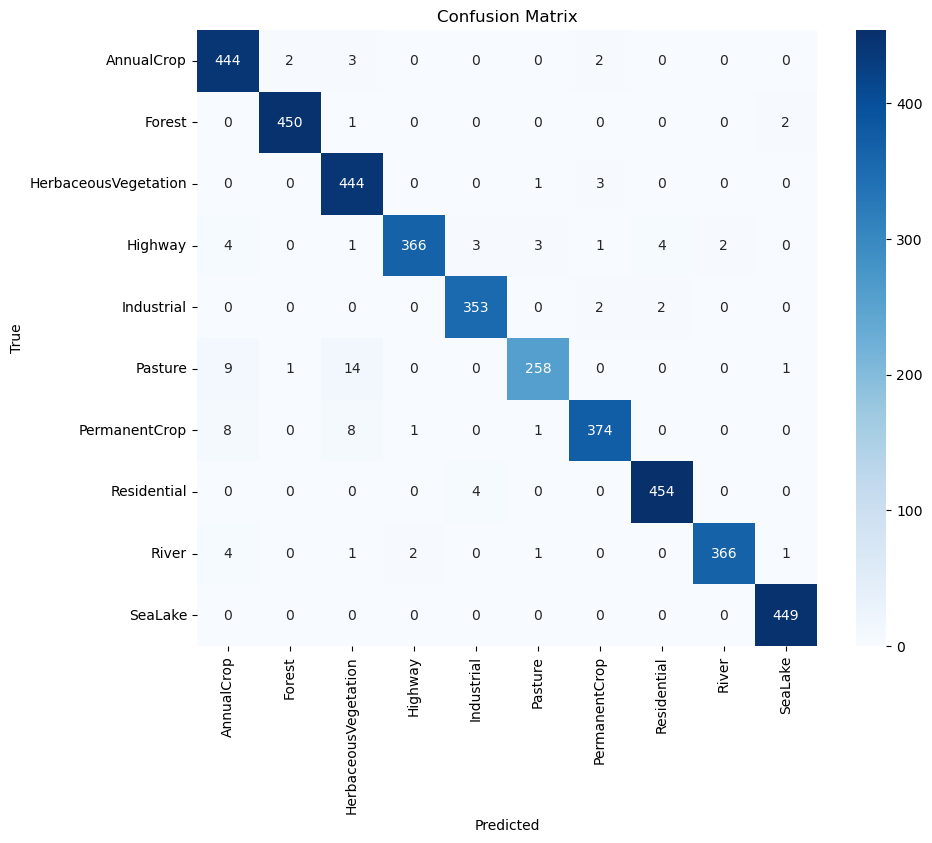

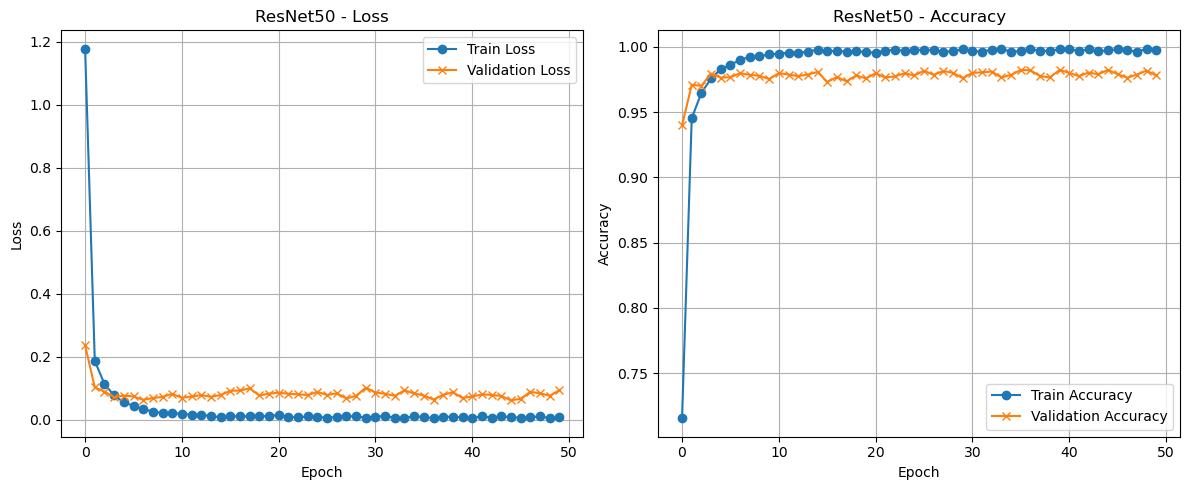

In [9]:
# Load ResNet50
resnet = load_model('resnet50')
num_ftrs = resnet.fc.in_features

# 30% dropout
resnet.fc = nn.Sequential(
    nn.Dropout(0.3),         
    nn.Linear(num_ftrs, 10)  
)

# DataLoaders
batch_size = 64
train_loader = DataLoader(train_ds, batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size)
test_loader = DataLoader(test_ds, batch_size)

# Training
resnet, resnet_time, tr_loss, tr_acc, val_acc, val_loss = train_model(resnet, train_loader, val_loader, epochs=50, use_scheduler=False)
print('Finished Training')

# Evaluation
y_true, y_pred = evaluate_model(resnet, test_loader)

# Plot Confusion Matrix, metrics
plot_confusion_matrix(y_true, y_pred, class_names)
plot_metrics(tr_loss, val_loss, tr_acc, val_acc, model_name='ResNet50')

Swin Transformer

Train Loss: 0.2353, Train Accuracy: 0.9234
Validation Loss: 0.1362, Validation Accuracy: 0.9583
Train Loss: 0.1315, Train Accuracy: 0.9579
Validation Loss: 0.0806, Validation Accuracy: 0.9736
Train Loss: 0.1098, Train Accuracy: 0.9643
Validation Loss: 0.2030, Validation Accuracy: 0.9444
Train Loss: 0.0873, Train Accuracy: 0.9724
Validation Loss: 0.0940, Validation Accuracy: 0.9706
Train Loss: 0.0862, Train Accuracy: 0.9730
Validation Loss: 0.1390, Validation Accuracy: 0.9578
Train Loss: 0.0707, Train Accuracy: 0.9782
Validation Loss: 0.0980, Validation Accuracy: 0.9686
Train Loss: 0.0311, Train Accuracy: 0.9890
Validation Loss: 0.0609, Validation Accuracy: 0.9825
Train Loss: 0.0285, Train Accuracy: 0.9910
Validation Loss: 0.0614, Validation Accuracy: 0.9812
Train Loss: 0.0244, Train Accuracy: 0.9919
Validation Loss: 0.0631, Validation Accuracy: 0.9810
Train Loss: 0.0221, Train Accuracy: 0.9928
Validation Loss: 0.0516, Validation Accuracy: 0.9837
Train Loss: 0.0226, Train Accuracy: 0.99

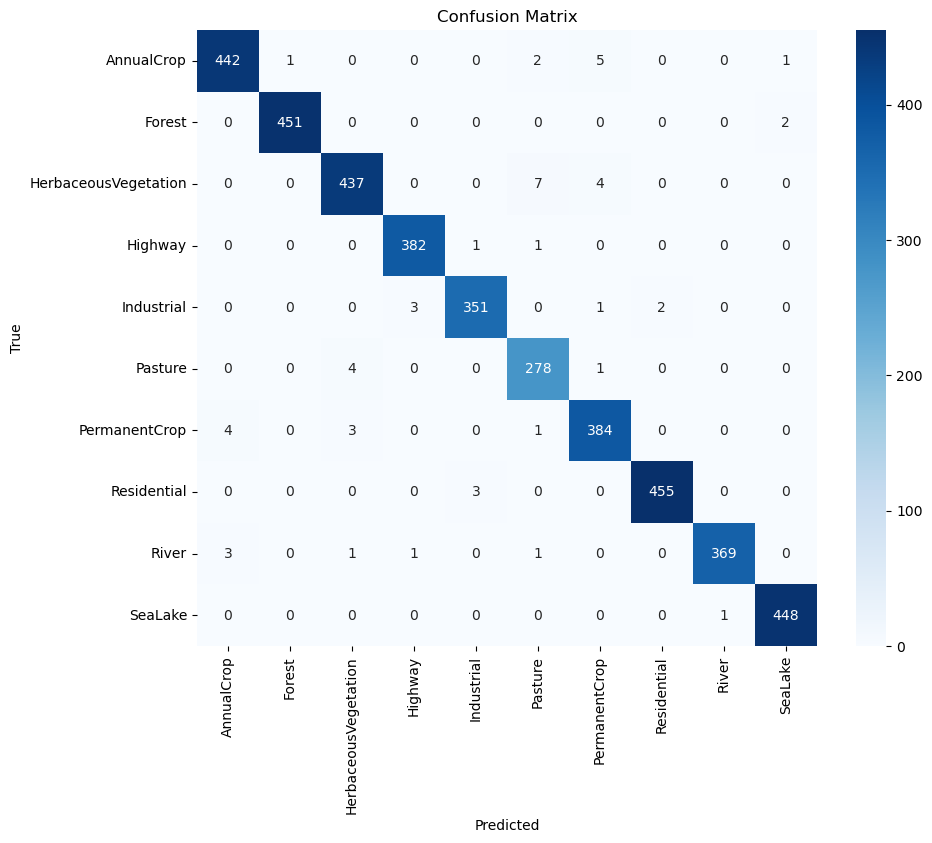

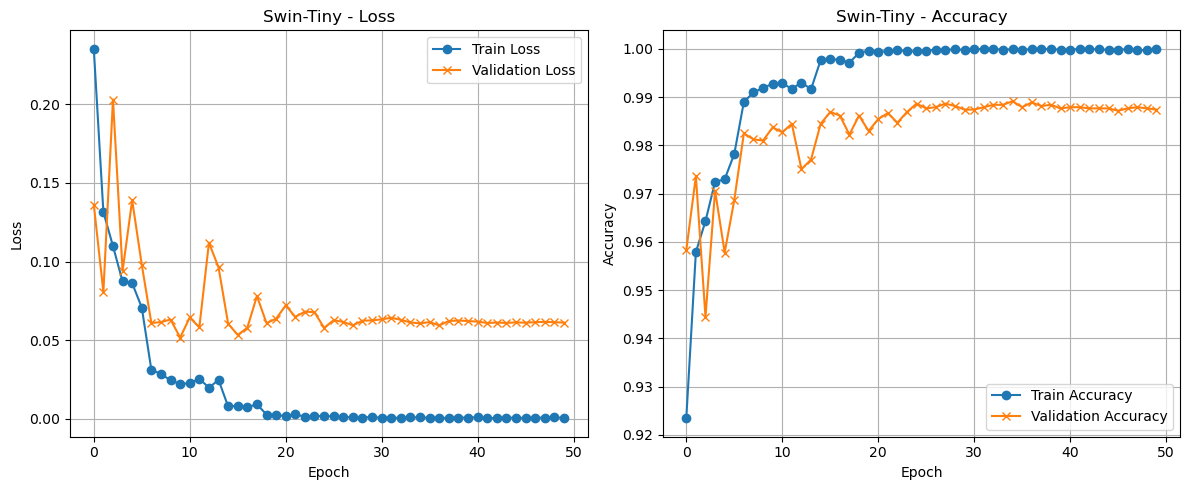

In [10]:
# Load Swin Tiny
swin = load_model('swin_tiny_patch4_window7_224')

# DataLoaders
batch_size = 8
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size)
test_loader = DataLoader(test_ds, batch_size=batch_size)

# Training
swin, swin_time, tr_loss_swin, tr_acc_swin, val_acc_swin, val_loss_swin = train_model(swin, train_loader, val_loader, epochs=50, use_scheduler=True)
print('Finished Training')

# Evaluation
y_true_swin, y_pred_swin = evaluate_model(swin, test_loader)

# Plot Confusion Matrix, metrics
plot_confusion_matrix(y_true_swin, y_pred_swin, class_names)
plot_metrics(tr_loss_swin, val_loss_swin, tr_acc_swin, val_acc_swin, model_name='Swin-Tiny')

EfficientNet

Train Loss: 0.4064, Train Accuracy: 0.8994
Validation Loss: 0.0786, Validation Accuracy: 0.9790
Train Loss: 0.0782, Train Accuracy: 0.9752
Validation Loss: 0.0546, Validation Accuracy: 0.9837
Train Loss: 0.0447, Train Accuracy: 0.9865
Validation Loss: 0.0515, Validation Accuracy: 0.9837
Train Loss: 0.0282, Train Accuracy: 0.9917
Validation Loss: 0.0460, Validation Accuracy: 0.9869
Train Loss: 0.0192, Train Accuracy: 0.9942
Validation Loss: 0.0530, Validation Accuracy: 0.9837
Train Loss: 0.0153, Train Accuracy: 0.9959
Validation Loss: 0.0579, Validation Accuracy: 0.9862
Train Loss: 0.0144, Train Accuracy: 0.9956
Validation Loss: 0.0504, Validation Accuracy: 0.9849
Train Loss: 0.0127, Train Accuracy: 0.9961
Validation Loss: 0.0567, Validation Accuracy: 0.9849
Train Loss: 0.0071, Train Accuracy: 0.9977
Validation Loss: 0.0467, Validation Accuracy: 0.9872
Train Loss: 0.0047, Train Accuracy: 0.9987
Validation Loss: 0.0450, Validation Accuracy: 0.9881
Train Loss: 0.0037, Train Accuracy: 0.99

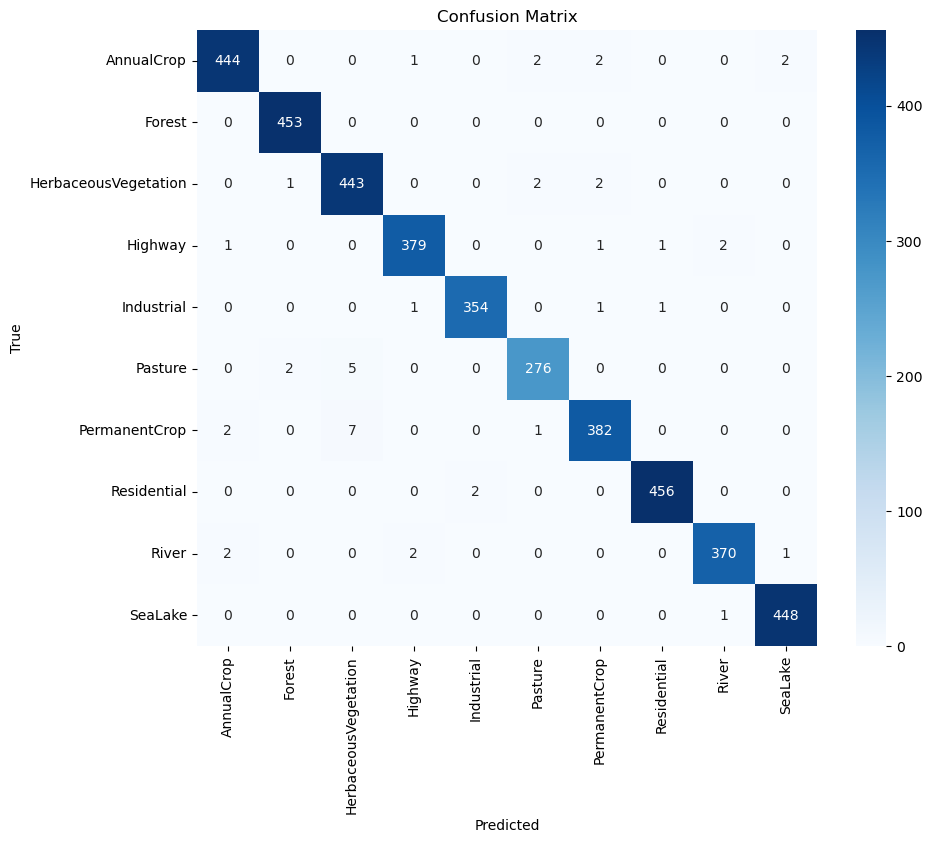

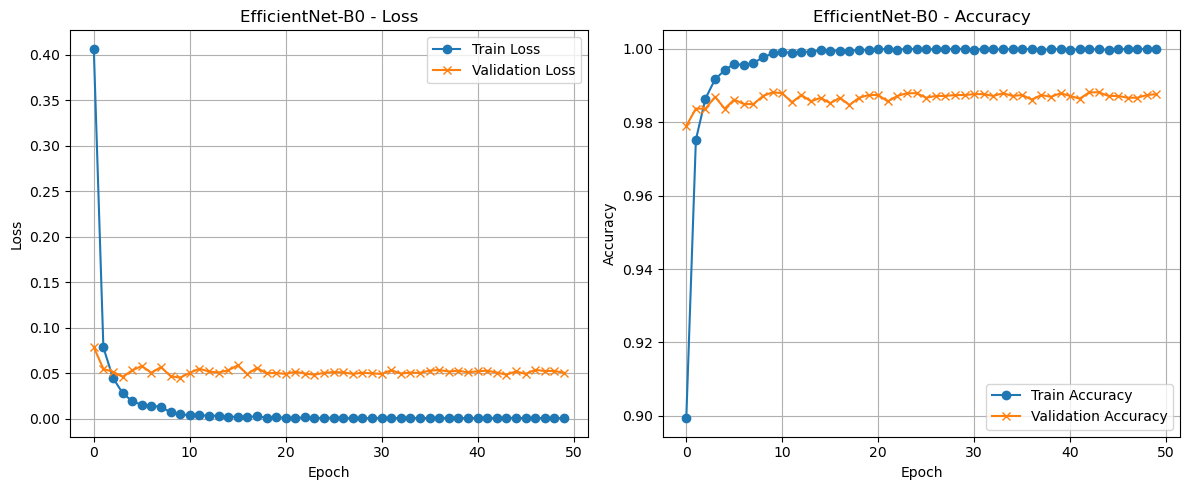

In [11]:
# Load EfficientNet-B0
effnet = load_model('efficientnet_b0')
in_features = effnet.classifier.in_features

# Dropout 30%
effnet.classifier = nn.Sequential(
    nn.Dropout(0.3),              
    nn.Linear(in_features, 10)    
)

# DataLoaders
batch_size = 64
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size)
test_loader = DataLoader(test_ds, batch_size=batch_size)

# Training
effnet, effnet_time, tr_loss_eff, tr_acc_eff, val_acc_eff, val_loss_eff = train_model(effnet, train_loader, val_loader, epochs=50, use_scheduler=True)
print('Finished Training')

# Evaluation
y_true_eff, y_pred_eff = evaluate_model(effnet, test_loader)

# Plot Confusion Matrix, metrics
plot_confusion_matrix(y_true_eff, y_pred_eff, class_names)
plot_metrics(tr_loss_eff, val_loss_eff, tr_acc_eff, val_acc_eff, model_name='EfficientNet-B0')

In [12]:
# Comparison
def plot_model_comparison(metrics_dict, metric_type='accuracy'):
    
    plt.figure(figsize=(10, 6))
    
    for model_name, metrics in metrics_dict.items():
        if metric_type == 'accuracy':
            val_acc = metrics[1]
            plt.plot(val_acc, label=f'{model_name} Validation Accuracy', marker='o')
        elif metric_type == 'loss':
            val_loss = metrics[3]
            plt.plot(val_loss, label=f'{model_name} Validation Loss', marker='x')
        else:
            raise ValueError("Metric_type must be 'accuracy' or 'loss'.")

    plt.title(f'Model Comparison - {metric_type.capitalize()}')
    plt.xlabel('Epoch')
    plt.ylabel(metric_type.capitalize())
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

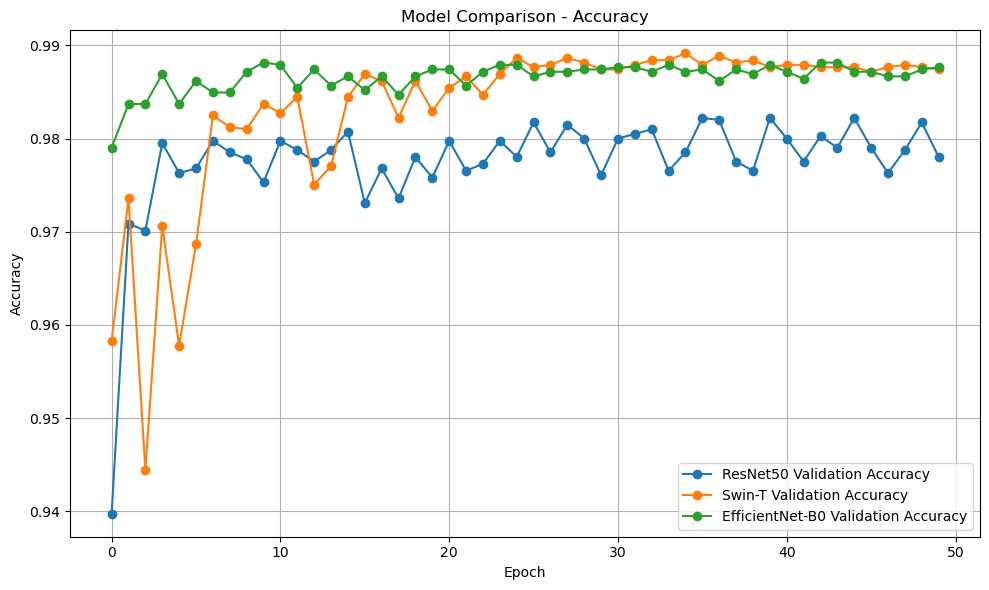

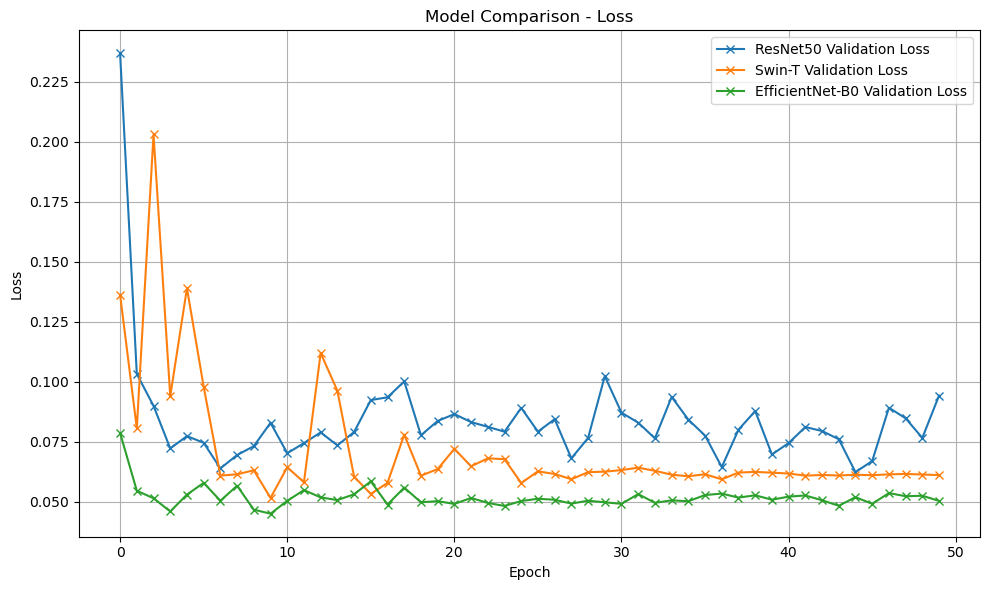

In [13]:
metrics_dict = {
    "ResNet50": [tr_acc, val_acc, tr_loss, val_loss],
    "Swin-T": [tr_acc_swin, val_acc_swin, tr_loss_swin, val_loss_swin],
    "EfficientNet-B0": [tr_acc_eff, val_acc_eff, tr_loss_eff, val_loss_eff]
}

plot_model_comparison(metrics_dict, metric_type='accuracy')
plot_model_comparison(metrics_dict, metric_type='loss')

In [14]:
# Plot images from dataset
unnormalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

def show_sample_images(dataset, class_names, num_images=9):
    plt.figure(figsize=(9, 9))
    for i in range(num_images):
        image, label = dataset[i]
        image = unnormalize(image)
        image = image.permute(1, 2, 0).numpy()  
        
        plt.subplot(3, 3, i+1)
        plt.imshow(image)
        plt.title(class_names[label])
        plt.axis('off')
    
    plt.suptitle("Examples from Dataset", fontsize=16)
    plt.tight_layout()
    plt.show()

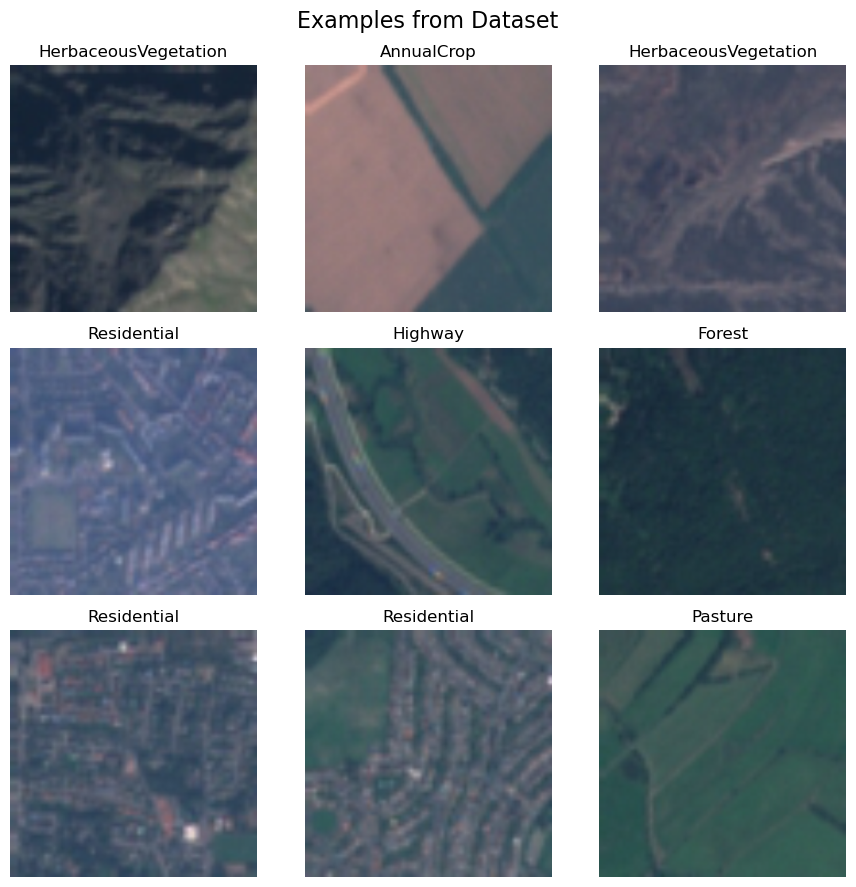

In [15]:
show_sample_images(train_ds, dataset.classes, num_images=9)

In [16]:
# Plot predictions
def show_predictions(model, dataset, class_names, num_images=9, device=None):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model.eval().to(device)

    unnormalize = transforms.Normalize(
        mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
        std=[1/0.229, 1/0.224, 1/0.225]
    )

    plt.figure(figsize=(12, 12))
    count = 0

    for i in range(len(dataset)):
        image, label = dataset[i]
        input_tensor = image.unsqueeze(0).to(device)

        with torch.no_grad():
            output = model(input_tensor)
            _, pred = torch.max(output, 1)

        image_disp = unnormalize(image).permute(1, 2, 0).cpu().numpy()
        pred_label = pred.item()
        true_label = label

        color = 'green' if pred_label == true_label else 'red'
        title = f"True: {class_names[true_label]}\nPred: {class_names[pred_label]}"

        plt.subplot(3, 3, count + 1)
        plt.imshow(image_disp)
        plt.title(title, color=color)
        plt.axis('off')

        count += 1
        if count >= num_images:
            break

    plt.suptitle("Model Predictions", fontsize=16)
    plt.tight_layout()
    plt.show()


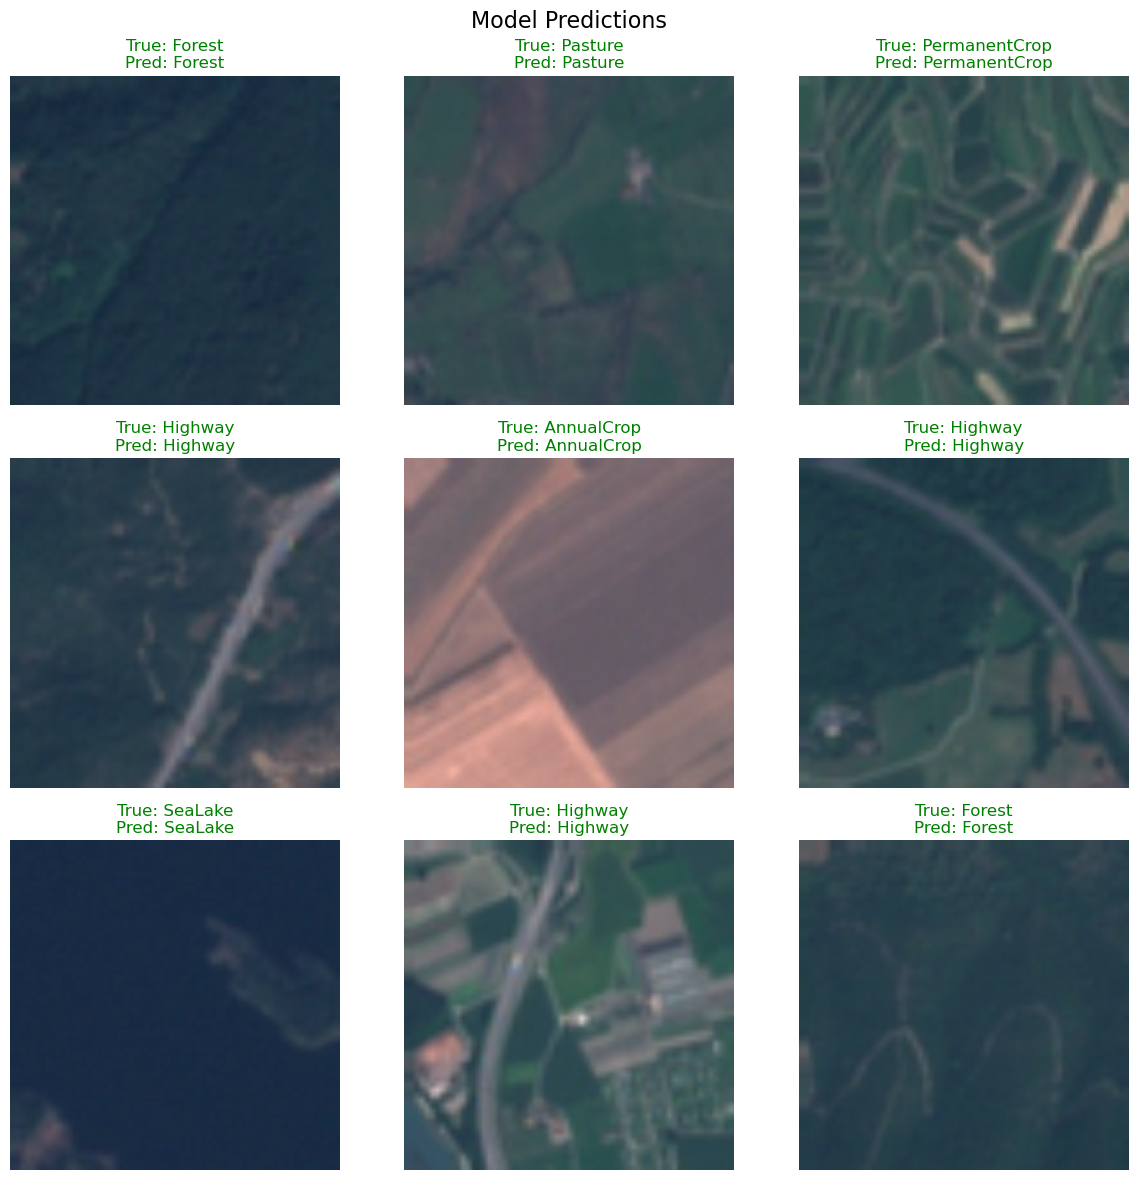

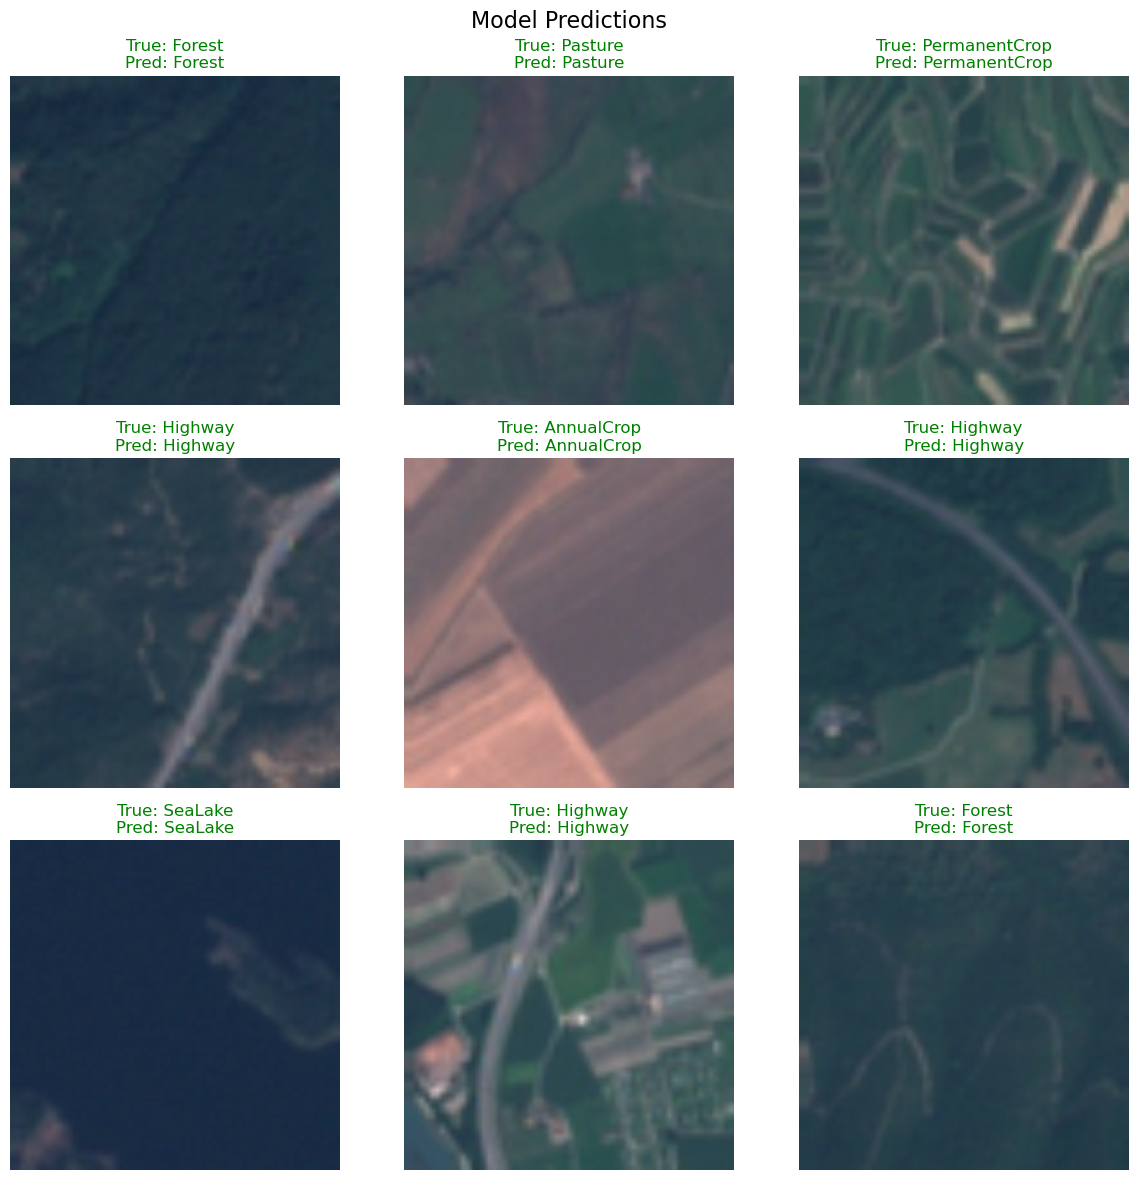

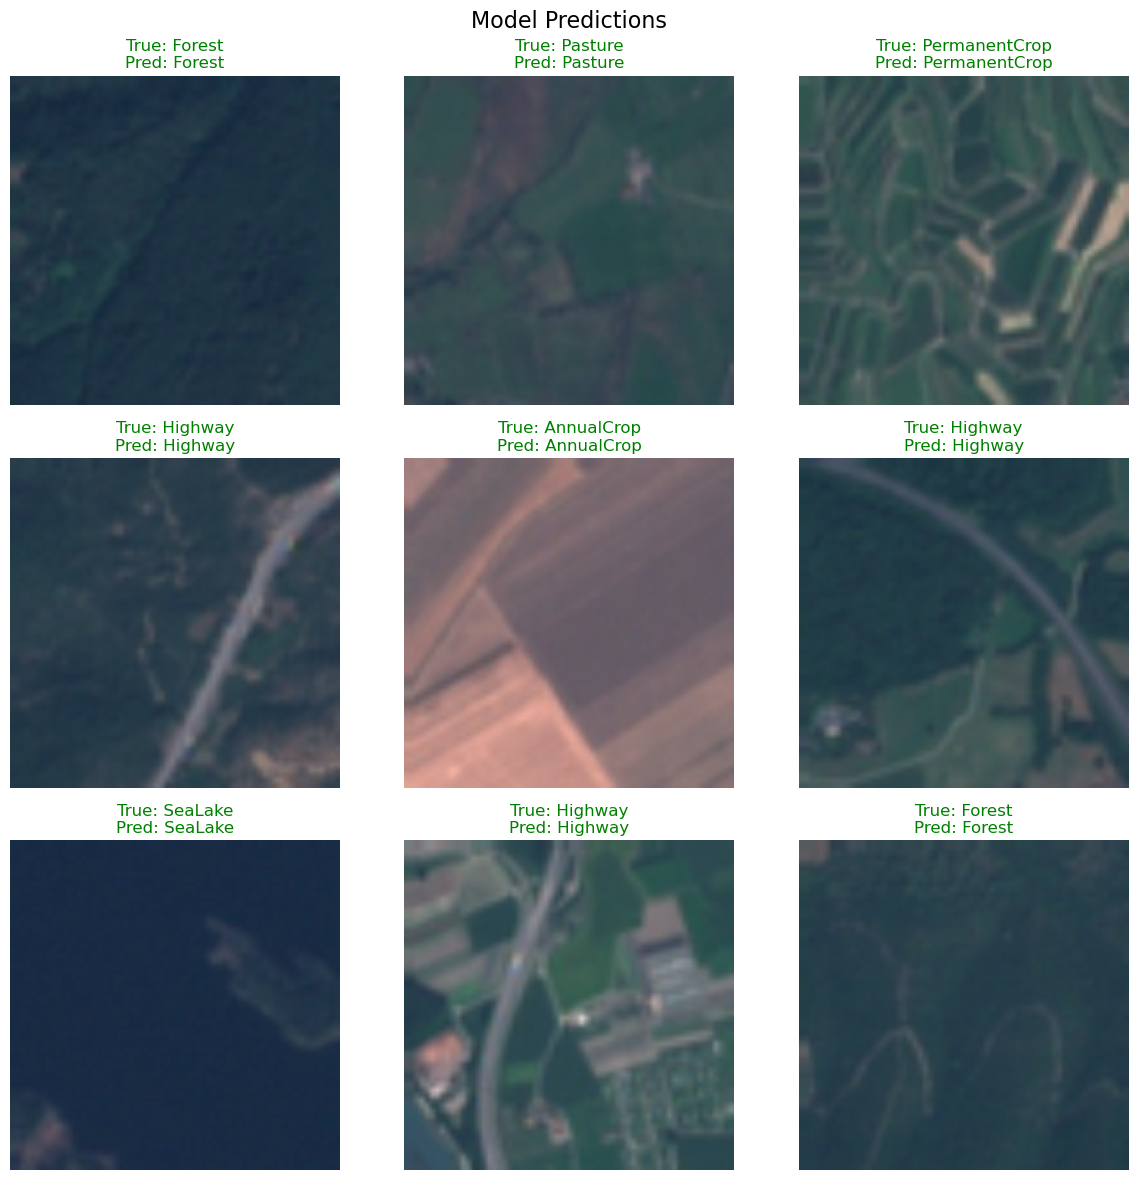

In [17]:
# ResNet:
show_predictions(resnet, test_ds, dataset.classes)

# Swin:
show_predictions(swin, test_ds, dataset.classes)

# EfficientNet:
show_predictions(effnet, test_ds, dataset.classes)
